# PINNs for the viscous Burgers equation: the forward problem

*PINNs course · Nassim RAZAALY*

We solve the viscous Burgers equation with a physics-informed neural network (PINN), step by step:

1. **The problem**: the equation, its exact solution (Cole–Hopf), data generation, the training points.
2. **Derivatives**: how automatic differentiation gives $u_x$, $u_t$, $u_{xx}$, first on the simplest possible model.
3. **The PINN**: the network, the loss, the training (Adam, then L-BFGS), and tools to evaluate a trained model.
4. **Exercises: how to do better?** Reliability, the optimizer, the points, the network, the loss. Solutions in `c_correction.ipynb`.

The notebook is self-contained: it only needs `numpy`, `torch` and `matplotlib`, and runs in about 4 minutes on a laptop CPU.

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

DTYPE = torch.float32                      # precision of the whole notebook (float32 is the PyTorch default)
torch.set_default_dtype(DTYPE)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def to_torch(a):
    """numpy array -> torch tensor with the notebook precision, on the notebook device."""
    return torch.as_tensor(np.asarray(a), dtype=torch.get_default_dtype(), device=DEVICE)


def to_numpy(t):
    return t.detach().cpu().numpy()


def sci(v, d=1):
    """3.2e-04 -> $3.2\\cdot10^{-4}$ (used to write the numbers in the comments of this notebook)"""
    m, e = f'{v:.{d}e}'.split('e')
    return f'${m}$' if int(e) == 0 else f'${m}\\cdot10^{{{int(e)}}}$'


plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE, '| precision:', DTYPE, '| torch', torch.__version__)

device: cpu | precision: torch.float32 | torch 2.11.0+cpu


## 1. The problem

### 1.1 The viscous Burgers equation

$$\partial_t u + u\,\partial_x u = \nu\,\partial_{xx} u,\qquad x\in[-1,1],\ t\in[0,T],$$
$$u(x,0) = u_0(x) = -\sin(\pi x),\qquad u(-1,t) = u(1,t) = 0,\qquad \nu = \frac{0.01}{\pi}\approx 3.2\cdot10^{-3},\qquad T = 0.99.$$
This is the benchmark of Raissi *et al.* (J. Comput. Phys., 2019).

* The term $u\,\partial_x u$ is a **nonlinear advection**: each value of $u$ travels at the speed $u$. Here $u_0>0$ for $x<0$ and $u_0<0$ for $x>0$: both sides move towards $x=0$ and the profile steepens. Without viscosity, the characteristics $x = x_0 + u_0(x_0)\,t$ first cross at $t^* = 1/\max(-u_0') = 1/\pi\approx0.32$: a shock forms.
* The term $\nu\,\partial_{xx}u$ is a **diffusion**, which stops the steepening: instead of a shock, a smooth **front** forms at $x=0$. A front between the values $+U$ and $-U$ has the profile $-U\tanh\big(\frac{Ux}{2\nu}\big)$: its thickness is of the order of $\delta = \frac{2\nu}{U}\approx6\cdot10^{-3}$, and its slope at the center is $\frac{U^2}{2\nu}\approx157$, for $U=1$.

A front of width $0.3\,\%$ of the domain, with a slope of about 150: this is what makes the problem hard for a neural network.

In [2]:
NU = 0.01 / np.pi          # viscosity
X_MIN, X_MAX = -1.0, 1.0   # space interval
T_MAX = 0.99               # final time


def u0(x):
    """initial condition"""
    return -np.sin(np.pi * x)

### 1.2 The exact solution (Cole–Hopf)

The change of variables $u = -2\nu\,\partial_x\ln\varphi$ turns the Burgers equation into the heat equation $\partial_t\varphi = \nu\,\partial_{xx}\varphi$ (substitute to check). The initial condition becomes $\varphi(x,0) = \exp\big(-\frac{1}{2\nu}\int_0^x u_0(s)\,ds\big)$, proportional to $f(x) = \exp\big(-\frac{\cos(\pi x)}{2\pi\nu}\big)$, and the heat equation is solved by a convolution with the heat kernel $\frac{1}{\sqrt{4\pi\nu t}}\,e^{-\eta^2/(4\nu t)}$. Since $f'(y) = \frac{\sin(\pi y)}{2\nu}f(y)$, this gives
$$u(x,t) = -\frac{\displaystyle\int_{\mathbb R}\sin\big(\pi(x-\eta)\big)\,f(x-\eta)\,e^{-\eta^2/(4\nu t)}\,d\eta}{\displaystyle\int_{\mathbb R} f(x-\eta)\,e^{-\eta^2/(4\nu t)}\,d\eta}.$$
This formula is **exact**. It gives the solution on $\mathbb R$ with the initial condition $-\sin(\pi x)$ on $\mathbb R$. This initial condition is odd and 2-periodic; since $-u(-x,t)$ and $u(x+2,t)$ also solve the Burgers equation with the same initial condition, by uniqueness the solution is odd and 2-periodic too. Therefore $u(\pm1,t)=-u(\mp1,t)=-u(\pm1,t)$, i.e. $u(\pm1,t)=0$: it is also the solution of our problem on $[-1,1]$.



In [3]:
def burgers_exact(x, t, nz=2001, L=12.0, chunk=1000):
    """Exact solution u(x, t) and its derivative u_x(x, t) by the Cole-Hopf formula.

    x, t: arrays of the same shape (or broadcastable). The two integrals are computed with the
    trapezoidal rule in z = eta / sqrt(4 nu t) on [-L, L], with a log-sum-exp to avoid overflow.
    """
    x, t = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(t, dtype=float))
    shape, x, t = x.shape, x.ravel(), t.ravel()
    z = np.linspace(-L, L, nz)
    u, ux = np.empty(x.size), np.empty(x.size)
    for i in range(0, x.size, chunk):                        # by chunks, to limit the memory
        xi, ti = x[i:i + chunk, None], t[i:i + chunk, None]
        y = xi - np.sqrt(4 * NU * ti) * z                    # y = x - eta
        E = -np.cos(np.pi * y) / (2 * np.pi * NU) - z ** 2   # log of the integrand (without the sine)
        w = np.exp(E - E.max(axis=1, keepdims=True))         # log-sum-exp: the largest term is 1
        S, C = np.sin(np.pi * y), np.cos(np.pi * y)
        num, den = (S * w).sum(1), w.sum(1)
        dw = w * S / (2 * NU)                                # d w / d x
        dnum, dden = (np.pi * C * w + S * dw).sum(1), dw.sum(1)
        u[i:i + chunk] = -num / den
        ux[i:i + chunk] = -(dnum * den - num * dden) / den ** 2
    return u.reshape(shape), ux.reshape(shape)


### 1.3 Data generation

Two functions generate exact data for any number of points: on a regular grid (the file `burgers.mat` of the course, `burgers_shock.mat` in the repository of Raissi *et al.*, is the $256\times100$ grid), or at random points, possibly with noise (useful for inverse problems). For the forward problem, the PINN does **not** use any value of $u$ inside the domain: these data only serve to evaluate it.

In [4]:
def make_grid_data(nx=256, nt=100):
    """Exact solution on a regular grid: x (nx,), t (nt,), U (nx, nt) with U[i, k] = u(x_i, t_k)."""
    x = np.linspace(X_MIN, X_MAX, nx)
    t = np.linspace(0, T_MAX, nt)
    U = burgers_exact(x[:, None], t[None, :])[0]
    return x, t, U


def make_scattered_data(n=2000, noise=0.0, seed=0):
    """n random points (x, t) in the domain, with the exact u (plus a Gaussian noise of relative level `noise`)."""
    rng = np.random.default_rng(seed)
    xt = np.c_[rng.uniform(X_MIN, X_MAX, n), rng.uniform(0, T_MAX, n)]
    u = burgers_exact(xt[:, 0], xt[:, 1])[0]
    return xt, u + noise * np.std(u) * rng.standard_normal(n)

x: (256,)  t: (100,)  U: (256, 100)   grid step dx = 7.84e-03


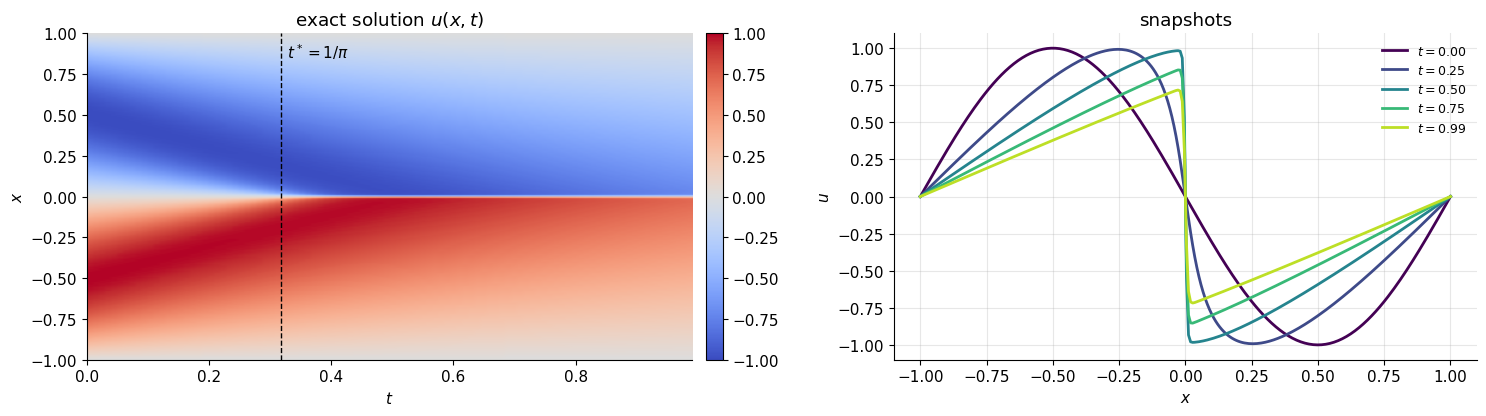

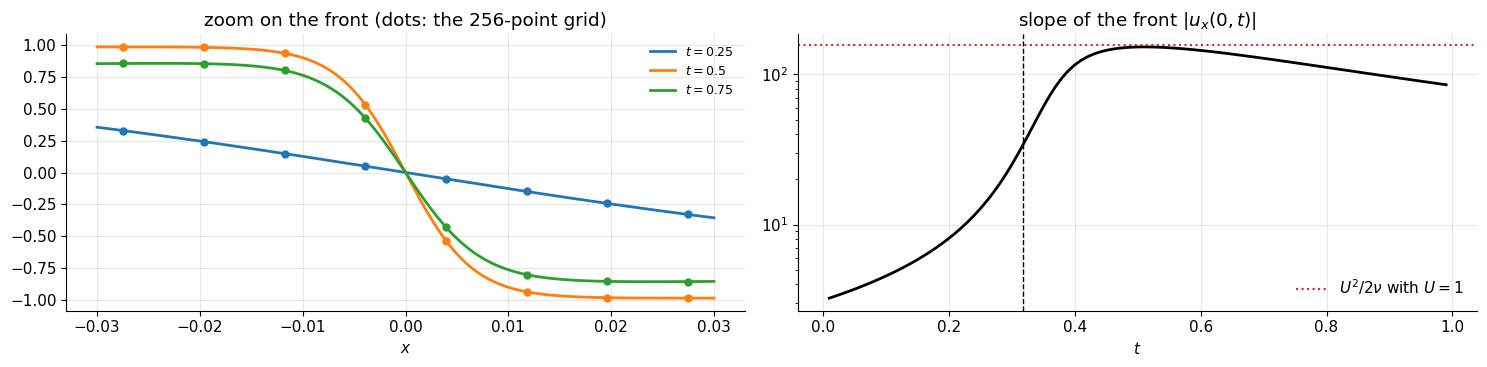

steepest slope 152 at t = 0.51; slope at t = 0.5: 152


In [5]:
x, t, U = make_grid_data(nx=256, nt=100)                   # the grid of the classical burgers.mat file
print('x:', x.shape, ' t:', t.shape, ' U:', U.shape, f'  grid step dx = {x[1] - x[0]:.2e}')

fig, axs = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={'width_ratios': [1.25, 1]})
im = axs[0].imshow(U, extent=[0, T_MAX, X_MIN, X_MAX], origin='lower', aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
axs[0].axvline(1 / np.pi, color='k', ls='--', lw=1); axs[0].text(1 / np.pi + 0.01, 0.85, r'$t^*=1/\pi$')
axs[0].set_xlabel('$t$'); axs[0].set_ylabel('$x$'); axs[0].set_title('exact solution $u(x,t)$'); axs[0].grid(False)
fig.colorbar(im, ax=axs[0], pad=0.02)
for k, c in zip([0, 25, 50, 75, 99], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    axs[1].plot(x, U[:, k], color=c, lw=2, label=f'$t = {t[k]:.2f}$')
axs[1].set_xlabel('$x$'); axs[1].set_ylabel('$u$'); axs[1].set_title('snapshots'); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

# the front: zoom, and its slope |u_x(0, t)| along time
xf = np.linspace(-0.03, 0.03, 601)
ts = np.linspace(0.01, T_MAX, 99)
slope = np.abs(burgers_exact(np.zeros_like(ts), ts)[1])
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8))
for tk, c in zip([0.25, 0.5, 0.75], ['tab:blue', 'tab:orange', 'tab:green']):
    axs[0].plot(xf, burgers_exact(xf, tk)[0], color=c, lw=2, label=f'$t = {tk}$')
    k = np.argmin(np.abs(t - tk)); sel = np.abs(x) < 0.03
    axs[0].plot(x[sel], U[sel, k], 'o', color=c, ms=5)
axs[0].set_xlabel('$x$'); axs[0].set_title('zoom on the front (dots: the 256-point grid)'); axs[0].legend(fontsize=9)
axs[1].semilogy(ts, slope, color='k', lw=2); axs[1].axvline(1 / np.pi, color='k', ls='--', lw=1)
axs[1].axhline(1 / (2 * NU), color='tab:red', ls=':', lw=1.5, label=r'$U^2/2\nu$ with $U=1$')
axs[1].set_xlabel('$t$'); axs[1].set_title(r'slope of the front $|u_x(0,t)|$'); axs[1].legend()
plt.tight_layout(); plt.show()
k_max = np.argmax(slope)
print(f'steepest slope {slope[k_max]:.0f} at t = {ts[k_max]:.2f}; slope at t = 0.5: {np.abs(burgers_exact(0.0, 0.5)[1]):.0f}')

The front appears around $t^*=1/\pi$; its slope reaches 152 at $t\approx0.51$, then decreases slowly as the amplitude $U$ on each side decreases. On the 256-point grid ($\Delta x = 7.8\cdot10^{-3}$, larger than the width of the front) the front is described by one or two grid values: to evaluate a model **precisely**, we will use a finer grid (Section 3.3).

### 1.4 The training points

The PINN needs three sets of points:
* **residual (collocation) points** $(x_i,t_i)$ inside the domain, where the residual of the PDE is minimized;
* **initial points** $(x_j,0)$, where $u_\theta$ must equal $u_0$ (equispaced in $x$);
* **boundary points** $(\pm1,t_k)$, where $u_\theta$ must vanish.

The residual points (and the boundary times) are drawn by **Latin hypercube sampling** (LHS): each coordinate is divided into $N_r$ bins, and each bin receives exactly one point. The coverage is more even than with independent uniform draws, at the same cost.

In [6]:
def lhs(n, dim, rng):
    """Latin hypercube sample of n points in [0, 1]^dim: in each dimension, one point in each of the n bins."""
    bins = np.stack([rng.permutation(n) for _ in range(dim)], axis=1)
    return (bins + rng.random((n, dim))) / n


def sample_points(n_r=5000, n_0=50, n_b=50, method='lhs', seed=0):
    """Training points: n_r residual (collocation) points inside the domain, n_0 initial points, n_b boundary times."""
    rng = np.random.default_rng(seed)
    s = lhs(n_r, 2, rng) if method == 'lhs' else rng.random((n_r, 2))
    xt_r = np.c_[X_MIN + (X_MAX - X_MIN) * s[:, 0], T_MAX * s[:, 1]]
    x_0 = np.linspace(X_MIN, X_MAX, n_0)
    t_b = T_MAX * lhs(n_b, 1, rng)[:, 0]
    xt_b = np.r_[np.c_[np.full(n_b, X_MIN), t_b], np.c_[np.full(n_b, X_MAX), t_b]]
    return {'r': to_torch(xt_r),                                   # (n_r, 2)  residual points
            'x0': to_torch(np.c_[x_0, np.zeros(n_0)]),             # (n_0, 2)  initial points (x, 0)
            'u0': to_torch(u0(x_0)[:, None]),                      # (n_0, 1)  u0(x)
            'b': to_torch(xt_b)}                                   # (2 n_b, 2) boundary points (-1, t), (1, t)

{'r': (5000, 2), 'x0': (50, 2), 'u0': (50, 1), 'b': (100, 2)}


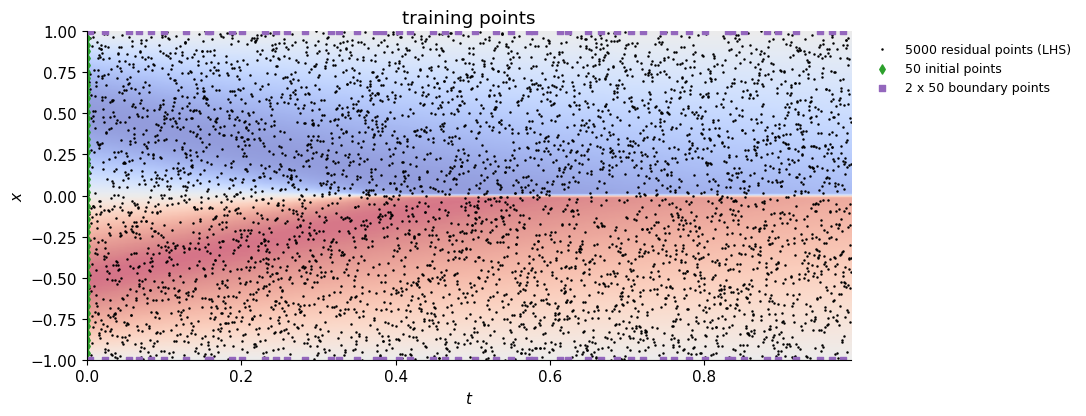

residual points inside the front (|x| < 2 nu, t > t*): 17 out of 5000


In [7]:
SEED = 1234                         # fixes the initialization of the network and the points
N_R, N_0, N_B = 5000, 50, 50        # residual points, initial points, boundary times (on each side)
pts = sample_points(N_R, N_0, N_B, seed=SEED)
print({k: tuple(v.shape) for k, v in pts.items()})

P, P0, PB = to_numpy(pts['r']), to_numpy(pts['x0']), to_numpy(pts['b'])
plt.figure(figsize=(11, 4.3))
plt.imshow(U, extent=[0, T_MAX, X_MIN, X_MAX], origin='lower', aspect='auto', cmap='coolwarm', vmin=-1, vmax=1, alpha=0.55)
plt.scatter(P[:, 1], P[:, 0], s=0.6, c='k', label=f'{N_R} residual points (LHS)')
plt.scatter(P0[:, 1], P0[:, 0], s=22, marker='d', c='tab:green', label=f'{N_0} initial points')
plt.scatter(PB[:, 1], PB[:, 0], s=16, marker='s', c='tab:purple', label=f'2 x {N_B} boundary points')
plt.xlabel('$t$'); plt.ylabel('$x$'); plt.title('training points'); plt.grid(False)
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9); plt.tight_layout(); plt.show()

in_front = np.sum((np.abs(P[:, 0]) < 2 * NU) & (P[:, 1] > 1 / np.pi))
print(f'residual points inside the front (|x| < 2 nu, t > t*): {in_front} out of {N_R}')

Only 17 of the 5000 residual points lie inside the front, where the solution changes the most. Keep this number in mind for the exercises.

## 2. Derivatives by automatic differentiation

### 2.1 The simplest model: one neuron

A PINN needs the derivatives of the network output with respect to its **inputs**. PyTorch computes them by automatic differentiation: these are exact derivatives (up to rounding), not finite differences. We start with a model whose derivatives we know, one neuron: $u(x) = \tanh(wx+b)$, with $u' = w\,(1-u^2)$ and $u'' = -2w^2\,u\,(1-u^2)$.

In [12]:
w = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)          # the two parameters of the model
b = torch.tensor(0.5, dtype=torch.float64, requires_grad=True)
x = torch.linspace(-2, 2, 9, dtype=torch.float64).reshape(-1, 1).requires_grad_(True)   # a batch of 9 inputs, (9, 1)
u = torch.tanh(w * x + b)                                                 # (9, 1)

# first and second derivatives with respect to the input x, at the 9 points
u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]        # (9, 1)
u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]   # (9, 1)

Two arguments matter:
* `grad_outputs=torch.ones_like(u)`: `torch.autograd.grad(outputs, inputs, grad_outputs=v)` returns the vector–Jacobian product $v^\top J$, of components $\sum_n v_n\,\partial u_n/\partial x_m$. Here $u_n$ only depends on $x_n$: the Jacobian $J$ is diagonal, and with $v=(1,\dots,1)$ the $m$-th component is $u'(x_m)$. We get **all the derivatives of the batch in one backward pass**.
* `create_graph=True`: the result $u_x$ is itself a differentiable function of $x$, $w$ and $b$. We need it twice: to compute $u_{xx}$, and, during training, to differentiate a loss that contains $u_x$ with respect to the parameters.


We then perform a numerical validation:

In [13]:
# ---- Numerical validation
# On u_x, u_xx: we know the analytical expression
print('max error on u_x  (analytical vs torch):', float((u_x - w * (1 - u ** 2)).abs().max()))
print('max error on u_xx:(analytical vs torch)', float((u_xx + 2 * w ** 2 * u * (1 - u ** 2)).abs().max()))

# On loss = MSE(du/dx): comparison with Finite Differences
loss = (u_x ** 2).mean()                       # MSE of du/dx
loss.backward()                                # propagate gradient loss

def loss_of(w_, b_):                           # Analytical loss, using du/dx = w(1-u^2), then its MSE
    v = torch.tanh(w_ * x.detach() + b_)
    return float((w_ * (1 - v ** 2)).pow(2).mean())

h = 1e-6
fd_w = (loss_of(w.detach() + h, b.detach()) - loss_of(w.detach() - h, b.detach())) / (2 * h)
print(f'd_loss/d_w: pytorch {float(w.grad):.5e}, finite differences {fd_w:.5e}, error {abs(fd_w)-float(w.grad):.5e}')

max error on u_x  (analytical vs torch): 9.606031248221569e-17
max error on u_xx:(analytical vs torch) 3.8424124992886277e-16
d_loss/d_w: pytorch 2.43379e-01, finite differences 2.43379e-01, error 1.15797e-10


### 2.2 Two inputs $(x,t)$, and a classic mistake

Now the input is a tensor `xt` of shape $(N,2)$, with columns $x$ and $t$. The gradient of $u$ with respect to `xt` has shape $(N,2)$: its columns are $u_x$ and $u_t$. To get $u_{xx}$, differentiate **the column $u_x$** and keep the first column of the result. We test it on one neuron with two inputs, $u = \tanh(ax+ct+b)$, for which $u_x = a(1-u^2)$, $u_t = c(1-u^2)$, $u_{xx} = -2a^2u(1-u^2)$ and $u_{xt} = -2ac\,u(1-u^2)$.

In [ ]:
a, c, b = 2.0, -1.5, 0.3
xt = torch.rand(100, 2, dtype=torch.float64).requires_grad_(True)       # 100 points (x, t)
u = torch.tanh(a * xt[:, 0:1] + c * xt[:, 1:2] + b)                       # (100, 1)

du = torch.autograd.grad(u, xt, torch.ones_like(u), create_graph=True)[0]          # (100, 2) = (u_x, u_t)
u_x, u_t = du[:, 0:1], du[:, 1:2]
u_xx = torch.autograd.grad(u_x, xt, torch.ones_like(u_x), create_graph=True)[0][:, 0:1]      # correct
wrong = torch.autograd.grad(du, xt, torch.ones_like(du), create_graph=True)[0][:, 0:1]      # a classic mistake

s = u * (1 - u ** 2)
print('u_x  error:', float((u_x - a * (1 - u ** 2)).abs().max()), '| u_t error:', float((u_t - c * (1 - u ** 2)).abs().max()))
print('u_xx error:', float((u_xx + 2 * a ** 2 * s).abs().max()))
print('"wrong" - u_xx         :', float((wrong + 2 * a ** 2 * s).abs().max()))
print('"wrong" - (u_xx + u_xt):', float((wrong + 2 * a ** 2 * s + 2 * a * c * s).abs().max()))

u_x  error: 2.220446049250313e-16 | u_t error: 2.220446049250313e-16
u_xx error: 8.881784197001252e-16
"wrong" - u_xx         : 2.309320601399175
"wrong" - (u_xx + u_xt): 4.440892098500626e-16

The "wrong" line differentiates the whole gradient `du` with `grad_outputs` = ones of shape $(N,2)$: autograd then differentiates the **sum of the two columns**, $u_x+u_t$, and the first column of the result is $u_{xx}+u_{tx}$. The code runs, the shapes are right, and the PDE is wrong. **Always test derivative code on a function whose derivatives you know.**

### 2.3 The derivatives of any model

We gather this in two functions. They work for any model that maps a tensor $(N,2)$ to a tensor $(N,1)$: a network, or a formula. We test them on $u(x,t) = e^{-t}\sin(\pi x)$, for which $r = u_t + u\,u_x - \nu u_{xx} = e^{-t}\sin(\pi x)\big(\nu\pi^2 - 1\big) + \pi e^{-2t}\sin(\pi x)\cos(\pi x)$.

In [ ]:
def derivatives(model, xt):
    """u, u_x, u_t, u_xx at the points xt (N, 2), by automatic differentiation."""
    xt = xt.clone().requires_grad_(True)
    u = model(xt)
    du = torch.autograd.grad(u, xt, torch.ones_like(u), create_graph=True)[0]       # (N, 2) = (u_x, u_t)
    u_x, u_t = du[:, 0:1], du[:, 1:2]
    u_xx = torch.autograd.grad(u_x, xt, torch.ones_like(u_x), create_graph=True)[0][:, 0:1]
    return u, u_x, u_t, u_xx


def pde_residual(model, xt):
    """r = u_t + u u_x - nu u_xx"""
    u, u_x, u_t, u_xx = derivatives(model, xt)
    return u_t + u * u_x - NU * u_xx

In [ ]:
def test_function(xt):
    return torch.exp(-xt[:, 1:2]) * torch.sin(torch.pi * xt[:, 0:1])

xt = to_torch(np.c_[np.random.default_rng(0).uniform(-1, 1, 1000), np.random.default_rng(1).uniform(0, T_MAX, 1000)])
X, T = xt[:, 0:1], xt[:, 1:2]
r_exact = torch.exp(-T) * torch.sin(torch.pi * X) * (NU * torch.pi ** 2 - 1) + torch.pi * torch.exp(-2 * T) * torch.sin(torch.pi * X) * torch.cos(torch.pi * X)
print('max |r_autograd - r_exact| =', float((pde_residual(test_function, xt) - r_exact).abs().max()))

max |r_autograd - r_exact| = 2.384185791015625e-07

The difference, of order $10^{-7}$, is the rounding error of float32.

## 3. The PINN

### 3.1 The network

The network of the course: the input $\mathbf z=(x,t)$ first goes through **Fourier features**
$$\gamma(\mathbf z) = \big[\sin(2\pi B\mathbf z),\ \cos(2\pi B\mathbf z)\big]\in\mathbb R^{16},\qquad B\in\mathbb R^{8\times2},\quad B_{ij}\sim\mathcal N(0,\sigma^2),\ \sigma=1,$$
with a **trainable** matrix $B$, then 8 hidden layers of 20 neurons with $\tanh$, and a linear output. Random Fourier features help a network represent fast variations, which plain MLPs learn slowly (the "spectral bias"). The activation must be smooth: the residual contains $u_{xx}$, which would vanish almost everywhere with ReLU. Weights: Xavier (Glorot) normal initialization; biases: zero.

In [ ]:
class PINN(nn.Module):
    """u_theta(x, t): Fourier features with a trainable matrix B, then an MLP with tanh activations."""

    def __init__(self, width=20, depth=8, n_fourier=8, sigma=1.0):
        super().__init__()
        self.B = nn.Parameter(sigma * torch.randn(n_fourier, 2)) if n_fourier > 0 else None
        sizes = [2 * n_fourier if n_fourier > 0 else 2] + [width] * depth + [1]
        self.layers = nn.ModuleList([nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])])
        for layer in self.layers:                                  # Xavier (Glorot) normal initialization
            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, xt):                                         # xt: (N, 2) -> u: (N, 1)
        h = xt
        if self.B is not None:
            z = 2 * torch.pi * xt @ self.B.T                       # (N, n_fourier)
            h = torch.cat([torch.sin(z), torch.cos(z)], dim=1)     # (N, 2 n_fourier)
        for layer in self.layers[:-1]:
            h = torch.tanh(layer(h))
        return self.layers[-1](h)


def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [ ]:
torch.manual_seed(SEED)
model = PINN(width=20, depth=8, n_fourier=8, sigma=1.0).to(DEVICE)
print(model)
print('trainable parameters d =', n_params(model), '= 16 (B) + 16x20+20 + 7 x (20x20+20) + 20+1')

PINN(
  (layers): ModuleList(
    (0): Linear(in_features=16, out_features=20, bias=True)
    (1-7): 7 x Linear(in_features=20, out_features=20, bias=True)
    (8): Linear(in_features=20, out_features=1, bias=True)
  )
)
trainable parameters d = 3317 = 16 (B) + 16x20+20 + 7 x (20x20+20) + 20+1

### 3.2 The loss

$$\mathcal L(\theta)=\underbrace{\frac{1}{N_r}\sum_{i=1}^{N_r}r_\theta(x_i,t_i)^2}_{\text{PDE residual}}+\underbrace{\frac{1}{N_0}\sum_{j=1}^{N_0}\big(u_\theta(x_j,0)-u_0(x_j)\big)^2}_{\text{initial condition}}+\underbrace{\frac{1}{2N_b}\sum_{k=1}^{N_b}\Big(u_\theta(-1,t_k)^2+u_\theta(1,t_k)^2\Big)}_{\text{boundary conditions}},\qquad r_\theta = \partial_tu_\theta+u_\theta\,\partial_xu_\theta-\nu\,\partial_{xx}u_\theta.$$
Three means with equal weights: the size of each term does not depend on its number of points, and its square root is an RMS value (a residual for the first term, an error on $u$ for the two others).

In [ ]:
def loss_terms(model, pts):
    """The three terms of the loss: mean squared PDE residual, initial error, boundary error."""
    r = pde_residual(model, pts['r'])
    e0 = model(pts['x0']) - pts['u0']
    eb = model(pts['b'])
    return {'pde': (r ** 2).mean(), 'ic': (e0 ** 2).mean(), 'bc': (eb ** 2).mean()}

In [ ]:
terms = loss_terms(model, pts)
print('initial loss terms:', {k: f'{float(v):.3e}' for k, v in terms.items()})

initial loss terms: {'pde': '3.294e+00', 'ic': '9.002e-01', 'bc': '1.102e-01'}

### 3.3 Tools to evaluate a model

To judge a trained model we compare it with the exact solution, which the training never sees:
* **the relative $L^2$ error** $\varepsilon = \|u_\theta-u\|_2/\|u\|_2$ on a reference grid of $1001\times100$ points ($\Delta x=0.002$, about a third of the width of the front, so that the grid resolves the front);
* the **maximal pointwise error** and where it occurs, and the relative error at each time, $\varepsilon(t)$;
* the **mean squared residual on 20 000 fresh random points**, compared with the one on the training points: if it is much larger, the network fits the PDE at the training points but not between them.

`evaluate(model, pts)` returns all of this (and prints a one-line summary); `plot_snapshots`, `plot_errors` and `plot_history` draw the standard figures. The reference grid is computed once, by Cole–Hopf (about 10 s).

In [ ]:
X_REF, T_REF, U_REF = make_grid_data(nx=1001, nt=100)      # reference grid: dx = 0.002, never used for training
XT_REF = torch.tensor(np.stack(np.meshgrid(X_REF, T_REF, indexing='ij'), axis=-1).reshape(-1, 2), dtype=torch.float64)
XT_FRESH = torch.tensor(make_scattered_data(20000, seed=12345)[0], dtype=torch.float64)   # 20 000 fresh random points


def as_input(model, xt):
    """points (numpy or torch) -> tensor with the precision and the device of the model"""
    p = next(model.parameters())
    return torch.as_tensor(xt, dtype=p.dtype, device=p.device)


def predict(model, xt=None):
    """u_theta on the reference grid (shape (nx, nt)), or at the points xt (shape (N,))."""
    with torch.no_grad():
        if xt is None:
            return to_numpy(model(as_input(model, XT_REF))).reshape(U_REF.shape)
        return to_numpy(model(as_input(model, xt)))[:, 0]


def rel_l2(model):
    """relative L2 error on the reference grid"""
    return np.linalg.norm(predict(model) - U_REF) / np.linalg.norm(U_REF)


def evaluate(model, pts=None, name='model', verbose=True):
    """Accuracy of a trained model: errors on the reference grid, residual on fresh points (and on the training points)."""
    E = predict(model) - U_REF
    i, k = np.unravel_index(np.abs(E).argmax(), E.shape)
    res = {'eps': np.linalg.norm(E) / np.linalg.norm(U_REF),                             # relative L2 error
           'eps_t': np.linalg.norm(E, axis=0) / np.maximum(np.linalg.norm(U_REF, axis=0), 1e-12),  # per time
           'max_err': np.abs(E[i, k]), 'x_max': X_REF[i], 't_max': T_REF[k],
           'res_fresh': float(pde_residual(model, as_input(model, XT_FRESH)).pow(2).mean())}
    if pts is not None:
        res['res_train'] = float(pde_residual(model, pts['r']).pow(2).mean())
    if verbose:
        msg = (f"{name}: eps = {res['eps']:.2e} | max error {res['max_err']:.1e} at (x, t) = ({res['x_max']:+.3f}, "
               f"{res['t_max']:.2f}) | residual MSE: fresh points {res['res_fresh']:.1e}")
        print(msg + (f", training points {res['res_train']:.1e}" if pts is not None else ''))
    return res

In [ ]:
def plot_snapshots(models, times=(0.0, 0.25, 0.5, 0.75, 0.99), zoom=0.05):
    """Exact solution and predictions at a few times; second row: zoom on the front (|x| < zoom)."""
    models = models if isinstance(models, dict) else {'PINN': models}
    xf = np.linspace(-zoom, zoom, 401)
    fig, axs = plt.subplots(2, len(times), figsize=(3.6 * len(times), 6.2), sharey='row')
    for j, t in enumerate(times):
        for ax, x in zip(axs[:, j], [X_REF, xf]):
            ax.plot(x, burgers_exact(x, t)[0], color='k', lw=2.4, alpha=0.35, label='exact')
            for (name, m), ls in zip(models.items(), ['--', ':', '-.', (0, (1, 1))]):
                ax.plot(x, predict(m, np.c_[x, np.full_like(x, t)]), ls=ls, lw=1.8, label=name)
            ax.set_xlabel('$x$')
        axs[0, j].set_title(f'$t = {t:.2f}$')
    axs[0, 0].set_ylabel('$u$'); axs[1, 0].set_ylabel(f'$u$, zoom $|x|<{zoom}$'); axs[0, 0].legend(fontsize=9)
    plt.tight_layout(); plt.show()


def plot_errors(model, pts=None):
    """Map of the pointwise error |u_theta - u| (log scale), with the residual points, and relative error per time."""
    from matplotlib.colors import LogNorm
    E = np.abs(predict(model) - U_REF)
    res = evaluate(model, verbose=False)
    fig, axs = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1.3, 1]})
    lo = E.max() * 1e-4                                            # color scale: 4 decades below the largest error
    im = axs[0].imshow(np.maximum(E, lo), extent=[0, T_MAX, X_MIN, X_MAX], origin='lower', aspect='auto',
                       cmap='magma_r', norm=LogNorm(vmin=lo, vmax=E.max()))
    if pts is not None:
        P = to_numpy(pts['r'])
        axs[0].scatter(P[:, 1], P[:, 0], s=0.2, c='tab:cyan', alpha=0.4)
    fig.colorbar(im, ax=axs[0], pad=0.02)
    axs[0].set_title(r'$|u_\theta - u|$' + (' and the residual points' if pts is not None else ''))
    axs[0].set_xlabel('$t$'); axs[0].set_ylabel('$x$'); axs[0].grid(False)
    axs[1].semilogy(T_REF, res['eps_t'], color='tab:red', lw=2)
    axs[1].axvline(1 / np.pi, color='k', ls=':', lw=1)
    axs[1].set_xlabel('$t$'); axs[1].set_title(r'relative $L^2$ error at time $t$ (dotted: $t^*=1/\pi$)')
    plt.tight_layout(); plt.show()


def plot_history(hist):
    """Loss terms and error eps along the iterations (dotted lines: change of optimizer)."""
    fig, axs = plt.subplots(1, 2, figsize=(15, 4))
    axs[0].semilogy(hist['it'], hist['loss'], color='tab:blue', lw=2.2, alpha=0.5, label='total loss')
    for k, c, lab in [('pde', '0.2', 'PDE residual'), ('ic', 'tab:green', 'initial condition'), ('bc', 'tab:purple', 'boundary')]:
        axs[0].semilogy(hist['it'], hist[k], color=c, lw=1.4, label=lab)
    axs[0].set_title('loss and its three terms'); axs[0].legend()
    axs[1].semilogy(hist['it'], hist['eps'], color='tab:red', lw=1.8)
    axs[1].set_title(r'relative $L^2$ error $\varepsilon$ (monitoring only)')
    for ax in axs:
        ax.set_xlabel('iteration')
        for it, name in hist.marks[1:]:
            ax.axvline(it, color='k', ls=':', lw=1)
    plt.tight_layout(); plt.show()

In [ ]:
res0 = evaluate(model, pts, name='untrained network')

untrained network: eps = 1.07e+00 | max error 1.3e+00 at (x, t) = (-0.504, 0.02) | residual MSE: fresh points 3.2e+00, training points 3.3e+00

### 3.4 Training: Adam, then L-BFGS

We use two optimizers, one after the other, on the full set of points:
* **Adam** (`lr` $=10^{-3}$): a first-order method with adaptive steps, robust from a random initialization, but slow to reach a high accuracy;
* **L-BFGS**: a quasi-Newton method; it converges much faster near a minimum. The direction is $\mathbf p_k=-H_k\nabla\mathcal L(\theta_k)$, where $H_k\approx(\nabla^2\mathcal L)^{-1}$ is built from the last $m$ pairs (step $\mathbf s_k=\theta_{k+1}-\theta_k$, change of gradient $\mathbf q_k=\nabla\mathcal L(\theta_{k+1})-\nabla\mathcal L(\theta_k)$). The matrix is never formed: a two-loop recursion computes $H_k\nabla\mathcal L$ with $O(md)$ operations and memory, starting from $H^0_k=\frac{\mathbf s^\top\mathbf q}{\mathbf q^\top\mathbf q}I$.
* The step length $\eta$ along $\mathbf p_k$ is chosen by a **strong Wolfe line search**: sufficient decrease, $\mathcal L(\theta_k+\eta\mathbf p_k)\le\mathcal L(\theta_k)+c_1\eta\,\nabla\mathcal L(\theta_k)^\top\mathbf p_k$, and small slope, $|\nabla\mathcal L(\theta_k+\eta\mathbf p_k)^\top\mathbf p_k|\le c_2|\nabla\mathcal L(\theta_k)^\top\mathbf p_k|$, with $c_1=10^{-4}$, $c_2=0.9$. The second condition guarantees $\mathbf s_k^\top\mathbf q_k>0$, so that $H_k$ stays positive definite.

| L-BFGS argument | value | meaning |
|---|---|---|
| `lr` | 1 | first trial step $\eta=1$: the quasi-Newton step, then adjusted by the line search |
| `line_search_fn` | `'strong_wolfe'` | the step must satisfy the two Wolfe conditions |
| `history_size` | 50 | number $m$ of pairs $(\mathbf s_k,\mathbf q_k)$ kept |
| `max_iter`, `max_eval` | 100, 1000 | iterations and loss evaluations per call to `.step()`; we call it repeatedly |
| `tolerance_grad`, `tolerance_change` | 0 | no convergence test: we decide the number of iterations |

`train_lbfgs` stops earlier if a call to `.step()` does not move the parameters: this happens when the line search finds no decrease (typically in float32, when the changes of the loss reach the rounding level). The class `History` records the loss terms and the error $\varepsilon$ every 100 iterations; $\varepsilon$ is only **monitored**, never used for training.

In [ ]:
class History:
    """Records the loss terms and the error eps (monitoring only) along the iterations of one or several optimizers."""

    def __init__(self, every=100):
        self.every, self.it, self.t0 = every, 0, time.time()
        self.rows = {k: [] for k in ['it', 'time', 'loss', 'pde', 'ic', 'bc', 'eps']}
        self.marks = []                                            # (iteration, name) at each change of optimizer

    def log(self, model, terms):
        values = [self.it, time.time() - self.t0, sum(float(v) for v in terms.values()),
                  float(terms['pde']), float(terms['ic']), float(terms['bc']), rel_l2(model)]
        for k, v in zip(self.rows, values):
            self.rows[k].append(v)

    def __getitem__(self, k):
        return np.array(self.rows[k])

    def summary(self):
        return (f"{self.it} iterations, {self['time'][-1]:.0f} s | loss {self['loss'][-1]:.2e} (PDE {self['pde'][-1]:.1e}, "
                f"IC {self['ic'][-1]:.1e}, BC {self['bc'][-1]:.1e}) | eps = {self['eps'][-1]:.2e}")


def train_adam(model, pts, n_iter, hist, lr=1e-3):
    hist.marks.append((hist.it, 'Adam'))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for k in range(n_iter):
        opt.zero_grad()
        terms = loss_terms(model, pts)
        loss = sum(terms.values())
        loss.backward()
        if hist.it % hist.every == 0:
            hist.log(model, terms)
        opt.step()
        hist.it += 1
    hist.log(model, loss_terms(model, pts))


def train_lbfgs(model, pts, n_iter, hist, lr=1.0, history_size=50, line_search='strong_wolfe'):
    """L-BFGS of PyTorch, called repeatedly: each call to .step() performs at most hist.every iterations, then we record.
    Stops early if a call does not move the parameters (the line search found no decrease)."""
    hist.marks.append((hist.it, 'L-BFGS'))
    opt = torch.optim.LBFGS(model.parameters(), lr=lr, max_iter=hist.every, max_eval=10 * hist.every,
                            history_size=history_size, tolerance_grad=0.0, tolerance_change=0.0,
                            line_search_fn=line_search)

    def closure():
        opt.zero_grad()
        loss = sum(loss_terms(model, pts).values())
        loss.backward()
        return loss

    done = 0
    while done < n_iter:
        opt.param_groups[0]['max_iter'] = min(hist.every, n_iter - done)
        before = [p.detach().clone() for p in model.parameters()]
        opt.step(closure)
        n = opt.state[opt._params[0]]['n_iter']                    # iterations done since the start
        hist.it += n - done
        done = n
        hist.log(model, loss_terms(model, pts))
        if all(torch.equal(b, p) for b, p in zip(before, model.parameters())):
            print(f'L-BFGS: no decrease found by the line search, stop after {done} iterations')
            break

In [ ]:
N_ADAM, N_LBFGS = 2000, 5000          # iterations of each optimizer

hist = History(every=100)
train_adam(model, pts, N_ADAM, hist, lr=1e-3)
print('after Adam  :', hist.summary())
train_lbfgs(model, pts, N_LBFGS, hist)
print('after L-BFGS:', hist.summary())

after Adam  : 2000 iterations, 44 s | loss 4.96e-02 (PDE 1.9e-02, IC 3.0e-02, BC 5.5e-05) | eps = 3.28e-01
L-BFGS: no decrease found by the line search, stop after 4880 iterations
after L-BFGS: 6880 iterations, 178 s | loss 1.45e-06 (PDE 1.4e-06, IC 7.5e-08, BC 9.0e-09) | eps = 7.92e-04

### 3.5 Results

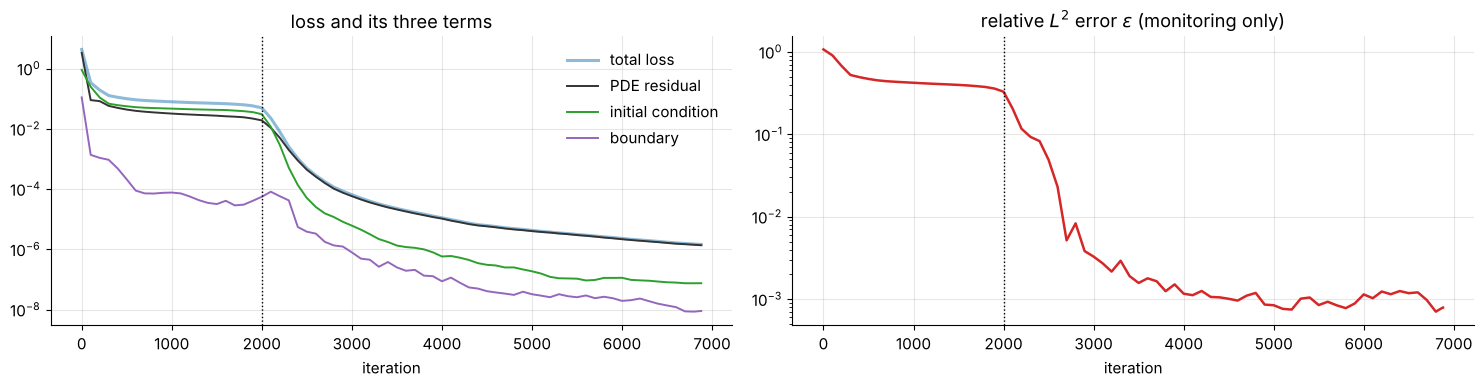

In [ ]:
plot_history(hist)
i_adam = list(hist['it']).index(N_ADAM)

**Reading.** After 2000 Adam iterations the error is $\varepsilon=$ $3.3\cdot10^{-1}$; L-BFGS then divides the loss by $3.4\cdot10^{4}$ and the error by 415, down to $\varepsilon=$ $7.9\cdot10^{-4}$. The loss measures the residuals of the PDE, of the initial and of the boundary conditions **at the training points**; $\varepsilon$ measures the distance to the exact solution **everywhere**. A small loss does not imply a small error (Exercise 0).

PINN (Adam + L-BFGS): eps = 7.92e-04 | max error 1.2e-02 at (x, t) = (+0.000, 0.72) | residual MSE: fresh points 7.9e-05, training points 1.4e-06

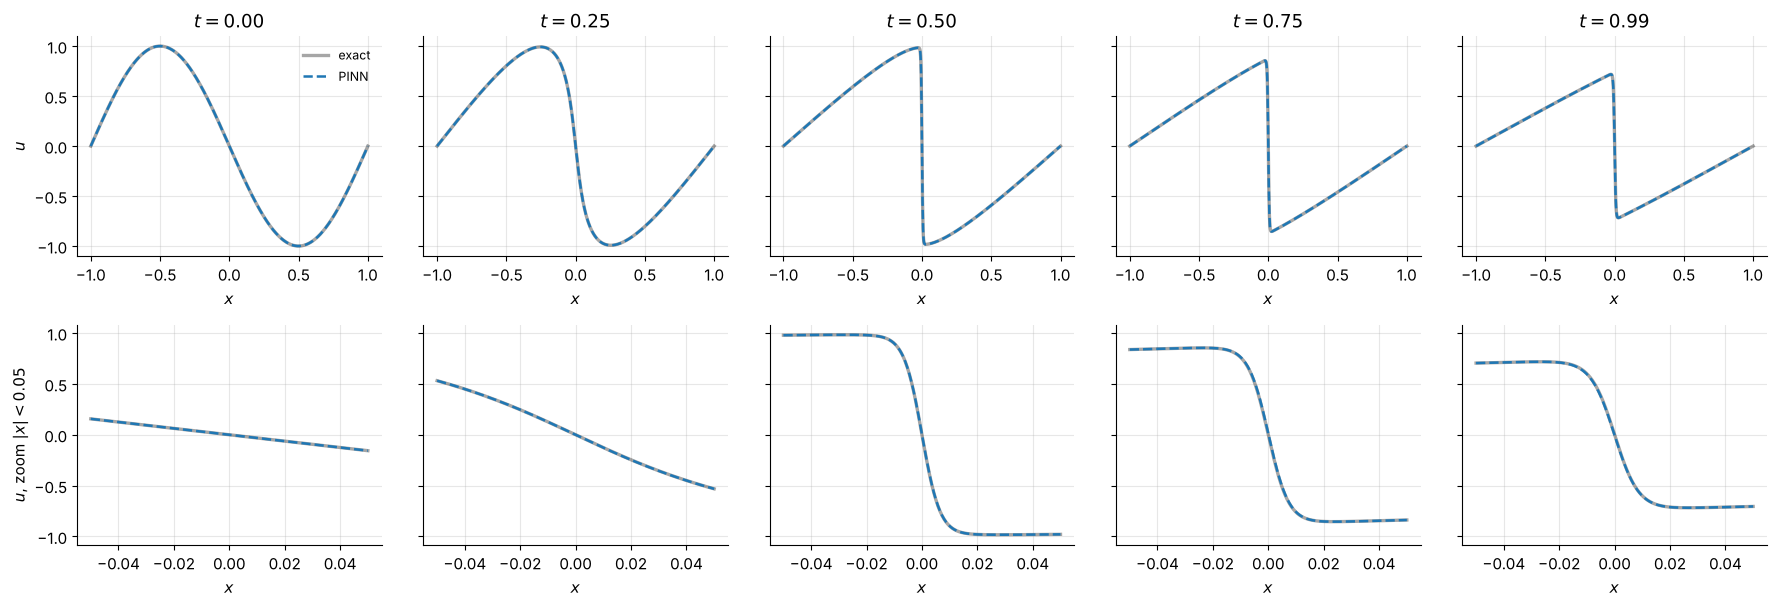

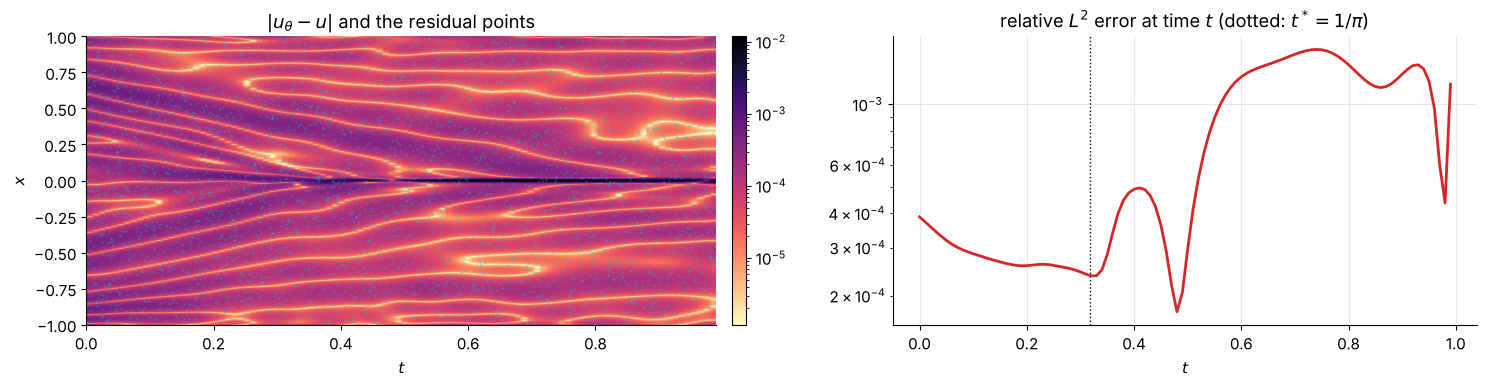

In [ ]:
res = evaluate(model, pts, name='PINN (Adam + L-BFGS)')
plot_snapshots(model)
plot_errors(model, pts)

**Reading.**
* The PINN reproduces the solution with $\varepsilon=$ $7.9\cdot10^{-4}$ (relative $L^2$ error on the $1001\times100$ grid).
* The largest error, $1.2\cdot10^{-2}$, is at $(x,t)=(+0.000,\ 0.72)$, in the front: the zoom (second row) shows where the network is least accurate.
* The error per time grows after the formation of the front ($t^*=1/\pi$).
* The mean squared residual is $1.4\cdot10^{-6}$ at the training points and $7.9\cdot10^{-5}$ on fresh points, 58 times larger: the network satisfies the PDE better at the points it was trained on than between them.

In [ ]:
print(f"{'':28s} {'value':>10s}")
for k, v in [('parameters', n_params(model)), ('iterations (Adam + L-BFGS)', hist.it),
             ('training time (s)', f"{hist['time'][-1]:.0f}"), ('final loss', f"{hist['loss'][-1]:.2e}"),
             ('relative L2 error eps', f"{res['eps']:.2e}"), ('max pointwise error', f"{res['max_err']:.2e}"),
             ('residual MSE, training', f"{res['res_train']:.1e}"), ('residual MSE, fresh', f"{res['res_fresh']:.1e}")]:
    print(f'{k:28s} {v!s:>10s}')

                                  value
parameters                         3317
iterations (Adam + L-BFGS)         6880
training time (s)                   178
final loss                     1.45e-06
relative L2 error eps          7.92e-04
max pointwise error            1.19e-02
residual MSE, training          1.4e-06
residual MSE, fresh             7.9e-05

## 4. Exercises: how to do better?

The PINN above is a correct, standard PINN. **Goal of the exercises: reach $\varepsilon\le10^{-4}$ reliably, with a training time of the order of 15 minutes on a CPU** (bonus: $10^{-5}$). The levers: the optimizer, the points, the network, and the loss.

Rules of the game, as in any experimental study:
* change **one thing at a time**, with the same seed (same initialization, same points);
* report the final loss, $\varepsilon$, the residual on fresh points and the training time, in a table;
* compare at a **similar cost**: wall time, or number of loss evaluations (an iteration of Adam, L-BFGS or BFGS does not cost the same);
* repeat your best candidates with **other seeds**: a difference smaller than the spread between seeds means nothing.

### Exercise 0 — Is the result reliable?
Set `SEED = 0` in Section 1.4 (it fixes both the points and the initialization), and run Sections 1.4 to 3.5 again; then `SEED = 1`. Compare $\varepsilon$ and look at the front (`plot_snapshots`). What goes wrong, and why can the loss be small while the solution is wrong? (The "Reading" cells are text: they do not change when you run the notebook again.)

### Exercise 1 — The optimizer
Start with the optimizer: as long as the loss is not well minimized, the other changes cannot be judged.
1. **Precision.** Set `DTYPE = torch.float64` at the top of the notebook and run again. Near convergence, the pairs $(\mathbf s_k,\mathbf q_k)$ of L-BFGS are differences of close numbers: how many significant digits does float32 keep?
2. **Settings.** Adam: `lr` $\in\{10^{-2},10^{-3},10^{-4}\}$, and the length of the warm-up (the number of Adam iterations before L-BFGS). L-BFGS: `history_size`, and without line search (`line_search=None` with `lr=0.1`, as in the course script `a_burgers.py`).
3. **Beyond L-BFGS: self-scaled BFGS.** The network has only $d=3317$ parameters, so a **full** $d\times d$ inverse-Hessian matrix $H$ fits in memory (88 MB in float64). Implement BFGS with a strong Wolfe line search (`from torch.optim.lbfgs import _strong_wolfe`) and the self-scaling of Al-Baali, used in recent PINN studies (Urbán *et al.*, J. Comput. Phys. 2025; Kiyani *et al.*, 2025). At each iteration:
$$\mathbf p_k=-H_k\nabla\mathcal L(\theta_k),\qquad \theta_{k+1}=\theta_k+\eta_k\mathbf p_k\ (\eta_k\text{ from the line search}),\qquad \mathbf s_k=\theta_{k+1}-\theta_k,\quad \mathbf q_k=\nabla\mathcal L(\theta_{k+1})-\nabla\mathcal L(\theta_k),$$
$$H_k\leftarrow\max(1,b_k)\,H_k,\quad b_k=\frac{-\eta_k\,\mathbf s_k^\top\nabla\mathcal L(\theta_k)}{\mathbf s_k^\top\mathbf q_k},\qquad H_{k+1}=\big(I-\rho_k\mathbf s_k\mathbf q_k^\top\big)H_k\big(I-\rho_k\mathbf q_k\mathbf s_k^\top\big)+\rho_k\mathbf s_k\mathbf s_k^\top,\quad\rho_k=\frac{1}{\mathbf q_k^\top\mathbf s_k}.$$
Here $b_k=\frac{\mathbf s_k^\top B_k\mathbf s_k}{\mathbf s_k^\top\mathbf q_k}$ with $B_k=H_k^{-1}$ (the second form above uses $\mathbf s_k=-\eta_kH_k\nabla\mathcal L(\theta_k)$ and avoids inverting $H_k$): when $b_k>1$, $H_k$ is too small along $\mathbf s_k$, and it is enlarged before the update (Al-Baali, 1998).

*Hints.* Work with the flattened vector of all the parameters ($\theta\in\mathbb R^d$). `_strong_wolfe(obj_func, x, t, d, f, g, gtd)` searches along the direction `d` from `x`, starting with the step `t`; `obj_func(x, t, d)` must return the loss and the flattened gradient at `x + t*d`, and `gtd` is $\nabla\mathcal L^\top\mathbf d$; it returns the new loss, the new gradient, the step and the number of evaluations (this is a private function of PyTorch). At the first iteration, start from $H_0=I$, then replace it by $\frac{\mathbf s_0^\top\mathbf q_0}{\mathbf q_0^\top\mathbf q_0}I$ instead of the scaling. Skip the update if $\mathbf s_k^\top\mathbf q_k\le0$. Use it after a short Adam warm-up (1000 iterations), in float64. Does it also fix Exercise 0?

### Exercise 2 — The points
1. **How many points?** Compare the mean squared residual at the training points and on fresh points, for the course PINN and for your best optimizer. Then train the course PINN with $N_r\in\{1000, 10000\}$. What happens with too few points?
2. **Resampling.** Replace the residual points by new random points every $K$ iterations (e.g. $K=500$). Why should the gap between the training residual and the fresh residual close? (With L-BFGS, create a new optimizer after each resampling: its stored pairs belong to the old loss.)
3. **Adaptive sampling (RAD).** Draw the new points among many uniform candidates (e.g. $10^5$), with a probability $p(\mathbf z)\propto\frac{|r_\theta(\mathbf z)|^k}{\mathbb E|r_\theta|^k}+c$ (Wu *et al.*, 2023; take $k=1$, $c=1$). Plot the points: where do they go? Compare with uniform resampling.

### Exercise 3 — The network
1. **Fourier features.** Compare with no Fourier features (`n_fourier=0`), and with a larger scale $\sigma$ (e.g. 5). Is the network of the course a good choice?
2. **Width and depth.** Compare networks (width $\times$ depth) with a similar number of parameters: $20\times8$ (3317), $26\times6$ (3995), $32\times4$ (3761).
3. **Hard constraints.** Write $u_\theta(x,t) = u_0(x) + t\,(1-x^2)\,N_\theta(x,t)$, where $N_\theta$ is the network. Check that the initial and boundary conditions now hold exactly, whatever $\theta$. Which terms of the loss remain? Does it help?
4. **Symmetry.** Prove the symmetry used in Section 1.2: the exact solution is odd in $x$, $u(-x,t)=-u(x,t)$. Build a network that is odd by construction, $u_\theta(x,t)=\frac12\big(N_\theta(x,t)-N_\theta(-x,t)\big)$. What is $u_\theta(0,t)$, whatever $\theta$? Where is the front?

### Exercise 4 — The loss
Plot the share of each term of the loss during the training. At the end, compare $\sqrt{\text{MSE}_{\mathrm{IC}}}$ and $\sqrt{\text{MSE}_{\mathrm{BC}}}$ (RMS errors on $u$ at the initial and boundary points) with the RMS error of $u$ in the domain. Would weights $\lambda_{\mathrm{IC}},\lambda_{\mathrm{BC}}\neq1$ in front of these terms help?

### Exercise 5 — Your best PINN
Combine what works, and report your best configuration over 3 seeds:

| configuration | iterations | time | final loss | $\varepsilon$ | residual MSE, fresh |
|---|---|---|---|---|---|
| this notebook (Adam + L-BFGS, float32) | | | | | |
| ... | | | | | |